# 01. Khám phá dữ liệu (EDA)

Mục tiêu: hiểu cấu trúc dữ liệu rượu vang đỏ, phân bố điểm chất lượng, mối liên hệ giữa các chỉ số hóa lý và nhãn nhị phân `quality >= 6`.

Kết quả của notebook này tương ứng mục 3.1 và 3.2 của báo cáo.

In [1]:
import os, sys
# Chạy từ thư mục notebooks/: chuyển về thư mục gốc dự án để đường dẫn tương đối hoạt động
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.data.preprocess import load_raw, make_labels, QUALITY_THRESHOLD
from src.utils import visualization as viz

pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
df = load_raw()
feats = [c for c in df.columns if c != "quality"]
y = make_labels(df)
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4000,0.7000,0.0000,1.9000,0.0760,11.0000,34.0000,0.9978,3.5100,0.5600,9.4000,5
1,7.8000,0.8800,0.0000,2.6000,0.0980,25.0000,67.0000,0.9968,3.2000,0.6800,9.8000,5
2,7.8000,0.7600,0.0400,2.3000,0.0920,15.0000,54.0000,0.9970,3.2600,0.6500,9.8000,5
3,11.2000,0.2800,0.5600,1.9000,0.0750,17.0000,60.0000,0.9980,3.1600,0.5800,9.8000,6
4,7.4000,0.7000,0.0000,1.9000,0.0760,11.0000,34.0000,0.9978,3.5100,0.5600,9.4000,5


## 1. Cấu trúc và chất lượng dữ liệu

In [2]:
print("Kích thước:", df.shape)
print("Giá trị thiếu:", int(df.isna().sum().sum()))
print("Bản ghi trùng lặp:", int(df.duplicated().sum()), f"({df.duplicated().mean():.1%})")
print("Điểm chất lượng nhỏ nhất / lớn nhất:", df.quality.min(), "/", df.quality.max())

Kích thước: (1599, 12)
Giá trị thiếu: 0
Bản ghi trùng lặp: 240 (15.0%)
Điểm chất lượng nhỏ nhất / lớn nhất: 3 / 8


In [3]:
df[feats].describe().T[["min", "mean", "max", "std"]].assign(skew=df[feats].skew())

,min,mean,max,std,skew
fixed acidity,4.6000,8.3196,15.9000,1.7411,0.9828
volatile acidity,0.1200,0.5278,1.5800,0.1791,0.6716
citric acid,0.0000,0.2710,1.0000,0.1948,0.3183
residual sugar,0.9000,2.5388,15.5000,1.4099,4.5407
chlorides,0.0120,0.0875,0.6110,0.0471,5.6803
free sulfur dioxide,1.0000,15.8749,72.0000,10.4602,1.2506
total sulfur dioxide,6.0000,46.4678,289.0000,32.8953,1.5155
density,0.9901,0.9967,1.0037,0.0019,0.0713
pH,2.7400,3.3111,4.0100,0.1544,0.1937
sulphates,0.3300,0.6581,2.0000,0.1695,2.4287


Bảng trên ứng với Bảng 3-1 trong báo cáo (thống kê và độ lệch của 11 thuộc tính).

## 2. Phân bố điểm chất lượng và nhãn

quality
3     10
4     53
5    681
6    638
7    199
8     18

Nhãn 1 (quality >= 6): 855 mẫu (53.47%)
Nhãn 0 (quality <  6): 744 mẫu (46.53%)


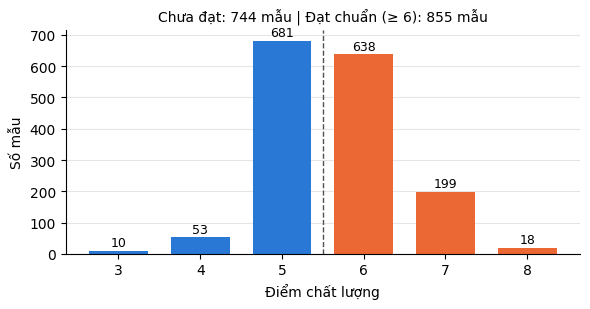

In [4]:
counts = df.quality.value_counts().sort_index()
print(counts.to_string())
print(f"\nNhãn 1 (quality >= {QUALITY_THRESHOLD}): {y.sum()} mẫu ({y.mean():.2%})")
print(f"Nhãn 0 (quality <  {QUALITY_THRESHOLD}): {(1 - y).sum()} mẫu ({1 - y.mean():.2%})")
fig = viz.plot_quality_distribution(df.quality, QUALITY_THRESHOLD)
viz.save(fig, "3_1_quality_distribution.png")
plt.show()

## 3. So sánh hai nhóm nhãn

In [5]:
group = pd.DataFrame({
    "tb_chua_dat": df[feats][y == 0].mean(),
    "tb_dat_chuan": df[feats][y == 1].mean(),
    "tuong_quan_voi_nhan": df[feats].corrwith(y),
})
group.sort_values("tuong_quan_voi_nhan", key=abs, ascending=False)

,tb_chua_dat,tb_dat_chuan,tuong_quan_voi_nhan
alcohol,9.9265,10.8550,0.4348
volatile acidity,0.5895,0.4741,-0.3214
total sulfur dioxide,54.6452,39.3520,-0.2320
sulphates,0.6185,0.6926,0.2181
citric acid,0.2378,0.2999,0.1591
density,0.9971,0.9965,-0.1591
chlorides,0.0930,0.0827,-0.1095
fixed acidity,8.1422,8.4740,0.0951
free sulfur dioxide,16.5672,15.2725,-0.0618
pH,3.3117,3.3106,-0.0033


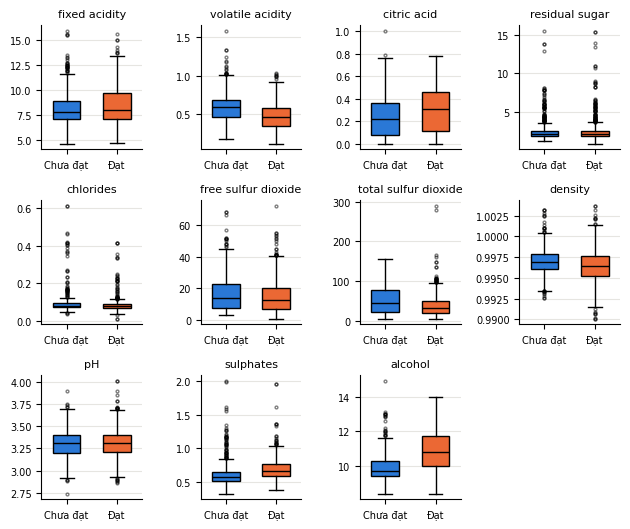

In [6]:
fig = viz.plot_boxplots(df[feats], y)
viz.save(fig, "3_2_boxplots_by_label.png")
plt.show()

Các hộp của hai nhóm chồng lấn ở mọi thuộc tính, nên không thuộc tính đơn lẻ nào tách được hai nhóm.

## 4. Tương quan giữa các thuộc tính

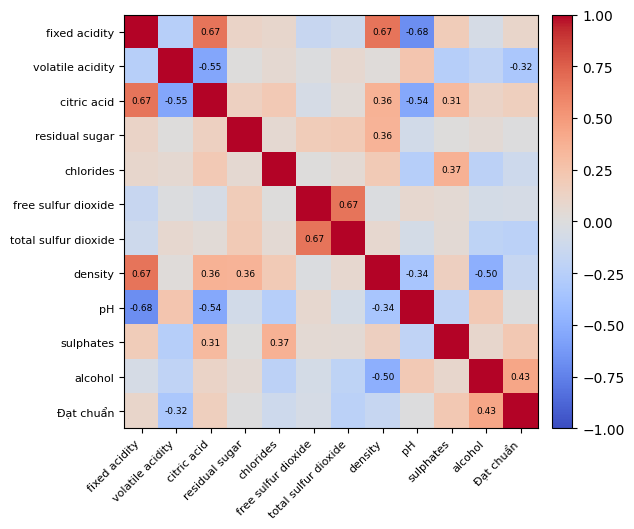

,thuoc_tinh_1,thuoc_tinh_2,r
0,fixed acidity,pH,-0.6830
1,fixed acidity,citric acid,0.6717
2,fixed acidity,density,0.6680
3,free sulfur dioxide,total sulfur dioxide,0.6677
4,volatile acidity,citric acid,-0.5525


In [7]:
fig = viz.plot_corr_heatmap(df[feats].assign(label=y).rename(columns={"label": "Đạt chuẩn"}))
viz.save(fig, "3_3_correlation_heatmap.png")
plt.show()

corr = df[feats].corr()
pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(feats) for b in feats[i + 1:]]
pd.DataFrame(sorted(pairs, key=lambda t: -abs(t[2]))[:5], columns=["thuoc_tinh_1", "thuoc_tinh_2", "r"])

## 5. Giá trị ngoại lai (quy tắc IQR, trên dữ liệu đã loại trùng)

In [8]:
d = df.drop_duplicates()
q1, q3 = d[feats].quantile(0.25), d[feats].quantile(0.75)
iqr = q3 - q1
mask = (d[feats] < q1 - 1.5 * iqr) | (d[feats] > q3 + 1.5 * iqr)
out = mask.sum().sort_values(ascending=False)
print(out.to_string())
print("\nTổng số giá trị bị đánh dấu:", int(out.sum()))

residual sugar          126
chlorides                87
sulphates                55
total sulfur dioxide     45
fixed acidity            41
density                  35
pH                       28
free sulfur dioxide      26
volatile acidity         19
alcohol                  12
citric acid               1

Tổng số giá trị bị đánh dấu: 475


## Nhận xét

- Với ngưỡng 6, hai lớp gần cân bằng.
- Nồng độ cồn và axit bay hơi liên hệ với nhãn rõ nhất.
- Không có thuộc tính nào tự tách được hai lớp, nên không kỳ vọng độ chính xác cao.
- Ngoại lai được giữ lại vì là kết quả đo thật.